# Email Spam Detection

**Goal:** decide whether an email is **Spam** or **Ham** (a normal, legitimate email).



In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

from text_utils import clean_text          # the SAME cleaning code the app uses

warnings.filterwarnings("ignore")
np.random.seed(42)
sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
enron = pd.read_csv("spam_ham_dataset.csv")        # main Enron dataset
extra = pd.read_csv("extra_emails.csv")            # extra everyday ham + modern spam (TRAINING)
external = pd.read_csv("external_test.csv")        # never used for training (TESTING ONLY)

print("Enron   :", enron.shape)
print("Extra   :", extra.shape, extra["label"].value_counts().to_dict())
print("External:", external.shape, external["label"].value_counts().to_dict())

Enron   : (5171, 4)
Extra   : (105, 3) {'ham': 75, 'spam': 30}
External: (45, 3) {'ham': 30, 'spam': 15}


In [3]:
print("Duplicate Enron texts:", enron["text"].duplicated().sum())
enron = enron.drop(columns=["Unnamed: 0"], errors="ignore")
enron = enron.drop_duplicates(subset="text").reset_index(drop=True)

print("After removing duplicates:", len(enron))
print(enron["label"].value_counts().to_dict())
print((enron["label"].value_counts(normalize=True) * 100).round(1).to_dict(), "(percent)")

Duplicate Enron texts: 178
After removing duplicates: 4993
{'ham': 3531, 'spam': 1462}
{'ham': 70.7, 'spam': 29.3} (percent)


In [4]:
low = enron["text"].str.lower()
checks = {"enron": "enron", "daren": "daren", "hpl": "hpl", "year 2000": "2000", "year 2001": "2001", "http": "http"}
rows = []
for name, pattern in checks.items():
    rows.append({"word": name,
                 "% of HAM containing it": round(low[enron.label == "ham"].str.contains(pattern).mean() * 100, 1),
                 "% of SPAM containing it": round(low[enron.label == "spam"].str.contains(pattern).mean() * 100, 1)})
pd.DataFrame(rows).set_index("word")

,% of HAM containing it,% of SPAM containing it
word,,
enron,40.9,0.0
daren,28.1,0.0
hpl,33.9,0.3
year 2000,41.9,2.9
year 2001,21.8,0.4
http,3.9,32.6


In [5]:
import inspect, text_utils
print(inspect.getsource(text_utils.clean_text))
print("Masked source words:", sorted(text_utils.SOURCE_WORDS)[:15], "...")

def clean_text(text: str) -> str:
    """Turn one raw email into a string of useful lowercase words."""
    text = str(text).lower()
    text = re.sub(r"^\s*subject\s*:", " ", text)        # constant 'subject:' tag
    text = _URL.sub(" urltoken ", text)                  # links -> one token
    text = _EMAIL_ADDR.sub(" emailtoken ", text)         # addresses -> one token
    text = re.sub(r"\s*'\s*t\b", " not", text)           # don ' t -> don not
    text = text.replace("$", " dollar ")
    text = _DATE_WORDS.sub(" ", text)                    # months / weekdays are Enron-era noise
    text = re.sub(r"\b(19|20)\d\d\b", " ", text)         # years (2000, 2001 ... = dataset era)
    text = re.sub(r"\d+", " number ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split()
              if w not in STOP_WORDS and w not in SOURCE_WORDS and len(w) > 1]
    return " ".join(tokens)

Masked source words: ['am', 'cc', 'clickathome', 'corp', 'daren', 'ect', 'ees', '

In [6]:
sample = "Subject: Hi Daren, meeting on Monday 4/3/2000 at http://x.com. Don't miss $500 FREE! mail me@x.com"
print("Original:", sample)
print("Cleaned :", clean_text(sample))

Original: Subject: Hi Daren, meeting on Monday 4/3/2000 at http://x.com. Don't miss $500 FREE! mail me@x.com
Cleaned : hi meeting number number urltoken don not miss dollar number free mail emailtoken


In [7]:
for df in (enron, extra, external):
    df["processed"] = df["text"].apply(clean_text)

print("Emails empty after cleaning:", int((enron["processed"].str.strip() == "").sum()))

Emails empty after cleaning: 3


label
ham     30
spam    15
Name: count, dtype: int64

label
ham     66.7 %
spam    33.3 %
Name: proportion, dtype: str


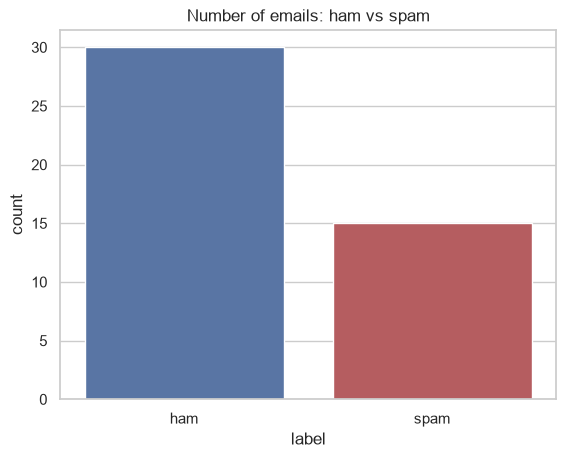

In [8]:
print(df["label"].value_counts())
print()
print((df["label"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

sns.countplot(x="label", data=df, palette=["#4C72B0", "#C44E52"])
plt.title("Number of emails: ham vs spam")
plt.show()

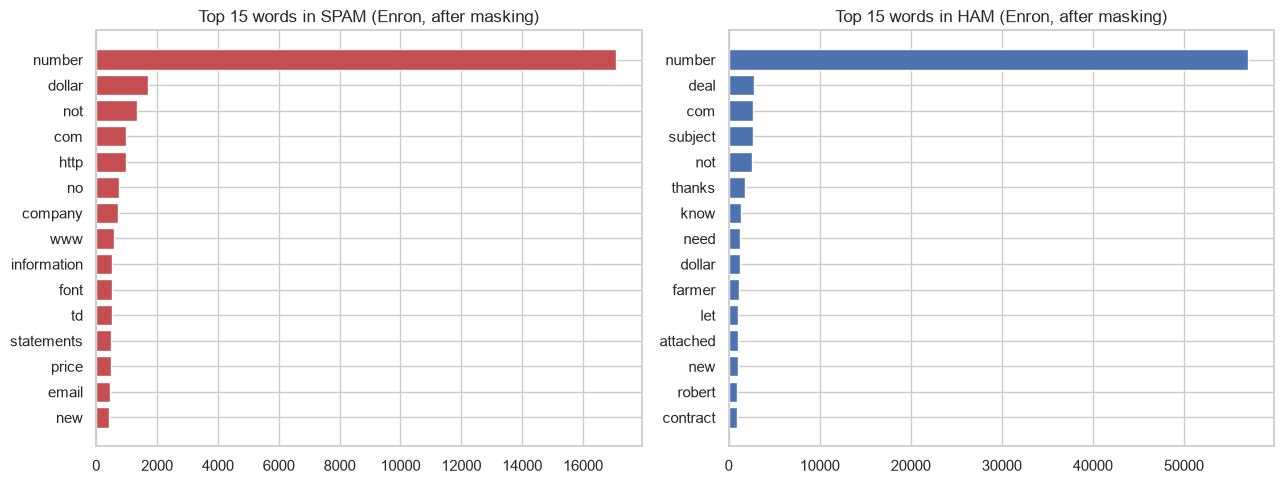

In [9]:
def top_words(df, label, n=15):
    words = " ".join(df.loc[df["label"] == label, "processed"]).split()
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, label, color in zip(axes, ["spam", "ham"], ["#C44E52", "#4C72B0"]):
    words, freq = zip(*top_words(enron, label))
    ax.barh(words[::-1], freq[::-1], color=color)
    ax.set_title(f"Top 15 words in {label.upper()} (Enron, after masking)")
plt.tight_layout()
plt.show()

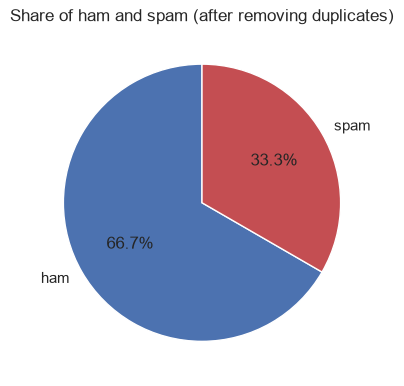

In [10]:
counts = df["label"].value_counts()
plt.figure(figsize=(4.5, 4.5))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"], startangle=90)
plt.title("Share of ham and spam (after removing duplicates)")
plt.show()

In [11]:
X_train_en, X_test_en, y_train_en, y_test_en = train_test_split(
    enron["processed"], enron["label_num"], test_size=0.2, random_state=42, stratify=enron["label_num"])

print("Enron train / test:", len(X_train_en), "/", len(X_test_en))
print("External test (kept completely separate):", len(external))

Enron train / test: 3994 / 999
External test (kept completely separate): 45


In [12]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
old_stop = set(ENGLISH_STOP_WORDS) - {"no", "nor", "not", "never"}

def old_clean(text):
    text = str(text).lower()
    text = re.sub(r"^subject:", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " url ", text)
    text = re.sub(r"\s*'\s*t\b", " not", text)
    text = text.replace("$", " dollar ")
    text = re.sub(r"\d+", " number ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(w for w in text.split() if w not in old_stop and len(w) > 1)

old_train = enron.loc[X_train_en.index, "text"].apply(old_clean)
old_test_en = enron.loc[X_test_en.index, "text"].apply(old_clean)
old_external = external["text"].apply(old_clean)

old_model = Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
                      ("clf", LinearSVC(random_state=42))])
old_model.fit(old_train, y_train_en)

def report(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    return {"Setup": name, "Precision": precision_score(y_true, y_pred), "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred), "Good mail -> spam": cm[0, 1], "Spam missed": cm[1, 0]}

baseline_rows = [report("OLD on Enron test", y_test_en, old_model.predict(old_test_en)),
                 report("OLD on EXTERNAL test", external["label_num"], old_model.predict(old_external))]
pd.DataFrame(baseline_rows).set_index("Setup").round(3)

,Precision,Recall,F1,Good mail -> spam,Spam missed
Setup,,,,,
OLD on Enron test,0.959,0.969,0.964,12,9
OLD on EXTERNAL test,0.556,1.000,0.714,12,0


In [13]:
EXTRA_WEIGHT = 5

X_train = pd.concat([X_train_en, extra["processed"]])
y_train = pd.concat([y_train_en, extra["label_num"]])
weights = np.r_[np.ones(len(X_train_en)), np.full(len(extra), EXTRA_WEIGHT)]

model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=5, random_state=42)),
])
model.fit(X_train, y_train, clf__sample_weight=weights)
print("Model trained.")

Model trained.


In [14]:
p_enron = model.predict_proba(X_test_en)[:, 1]
p_ext = model.predict_proba(external["processed"])[:, 1]

rows = []

for th in [0.5, 0.6, 0.7, 0.8, 0.9]:
    cm_a = confusion_matrix(y_test_en, p_enron >= th)
    cm_b = confusion_matrix(external["label_num"], p_ext >= th)
    rows.append({"threshold": th,
                 "Enron: good->spam": cm_a[0, 1], "Enron: spam missed": cm_a[1, 0],
                 "External: good->spam": cm_b[0, 1], "External: spam missed": cm_b[1, 0]})
pd.DataFrame(rows).set_index("threshold")

,Enron: good->spam,Enron: spam missed,External: good->spam,External: spam missed
threshold,,,,
0.5,17,11,5,0
0.6,12,20,1,1
0.7,8,29,1,1
0.8,6,39,0,1
0.9,3,86,0,3


In [15]:
THRESHOLD = 0.7      # chosen as a balance: few good emails blocked, spam recall still high

Enron test (threshold 0.7)
              precision    recall  f1-score   support

         Ham      0.960     0.989     0.974       706
        Spam      0.971     0.901     0.935       293

    accuracy                          0.963       999
   macro avg      0.965     0.945     0.954       999
weighted avg      0.963     0.963     0.963       999

EXTERNAL test (threshold 0.7)
              precision    recall  f1-score   support

         Ham      0.967     0.967     0.967        30
        Spam      0.933     0.933     0.933        15

    accuracy                          0.956        45
   macro avg      0.950     0.950     0.950        45
weighted avg      0.956     0.956     0.956        45



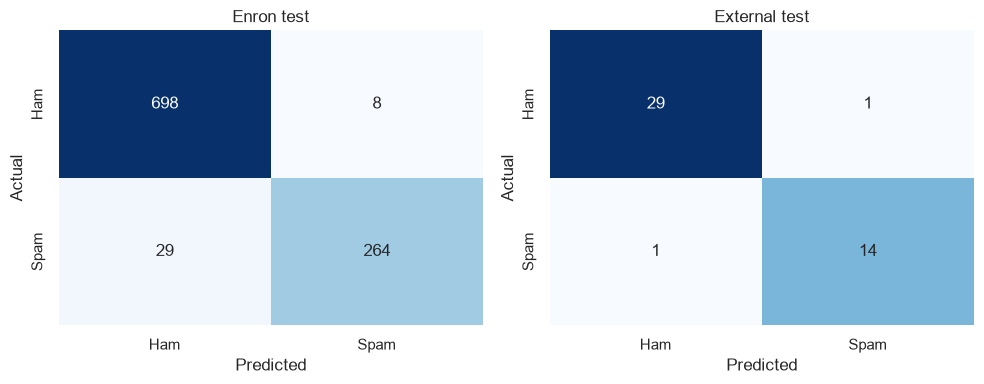

In [16]:
for name, X_, y_ in [("Enron test", X_test_en, y_test_en), ("EXTERNAL test", external["processed"], external["label_num"])]:
    pred = (model.predict_proba(X_)[:, 1] >= THRESHOLD).astype(int)
    print("=" * 60); print(name, f"(threshold {THRESHOLD})")
    print(classification_report(y_, pred, target_names=["Ham", "Spam"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, X_, y_) in zip(axes, [("Enron test", X_test_en, y_test_en), ("External test", external["processed"], external["label_num"])]):
    pred = (model.predict_proba(X_)[:, 1] >= THRESHOLD).astype(int)
    sns.heatmap(confusion_matrix(y_, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [17]:
names = np.array(model["tfidf"].get_feature_names_out())
coef = model["clf"].coef_[0]
order = np.argsort(coef)
print("Strongest HAM words :", list(names[order[:25]]))
print("Strongest SPAM words:", list(names[order[-25:]][::-1]))

Strongest HAM words : ['thanks', 'attached', 'bring', 'deal', 'tomorrow', 'questions', 'let know', 'number number', 'doc', 'month', 'team', 'received', 'let', 'plant', 'changes', 'reminder', 'farmer', 'deal number', 'class', 'urgent', 'number attached', 'change', 'bob', 'volume', 'following']
Strongest SPAM words: ['http', 'no', 'money', 'info', 'hot', 'paliourg', 'dollar', 'remove', 'click', 'investment', 'meds', 'site', 'vi', 'number email', 'international', 'stop', 'prices', 'loading', 'read', 'best', 'pain', 'low', 'software', 'biz', 'women']


In [18]:
def predict_email(email_text, threshold=THRESHOLD):
    processed = clean_text(email_text)
    p_spam = model.predict_proba([processed])[0, 1]
    label = "SPAM" if p_spam >= threshold else "HAM (legitimate)"
    print(f"{label:18s} spam probability = {p_spam * 100:5.1f}% | {email_text[:70]}")

tests = [
    "Hi John, are you free for lunch tomorrow? Let me know.",
    "Dear Professor, I could not attend the lecture yesterday due to illness. Please share the notes.",
    "Your OTP for login is 483920. Do not share it with anyone.",
    "Hi team, please find the attendance sheet attached for BSCS 5th semester.",
    "Subject: gas nomination for march. Daren, please confirm the volumes for the meter.",
    "Congratulations! You won a $1000 gift card. Click http://claim.com now!",
    "Your account is suspended. Verify your password at www.secure-bank-login.com immediately.",
    "Buy cheap meds online. No prescription needed. Lowest prices guaranteed.",
]
for t in tests:
    predict_email(t)

HAM (legitimate)   spam probability =   1.3% | Hi John, are you free for lunch tomorrow? Let me know.
HAM (legitimate)   spam probability =   8.3% | Dear Professor, I could not attend the lecture yesterday due to illnes
HAM (legitimate)   spam probability =  26.5% | Your OTP for login is 483920. Do not share it with anyone.
HAM (legitimate)   spam probability =   0.4% | Hi team, please find the attendance sheet attached for BSCS 5th semest
HAM (legitimate)   spam probability =  56.1% | Subject: gas nomination for march. Daren, please confirm the volumes f
SPAM               spam probability =  95.6% | Congratulations! You won a $1000 gift card. Click http://claim.com now
SPAM               spam probability =  84.8% | Your account is suspended. Verify your password at www.secure-bank-log
SPAM               spam probability =  99.7% | Buy cheap meds online. No prescription needed. Lowest prices guarantee


In [19]:
joblib.dump({"model": model, "threshold": THRESHOLD}, "spam_model.pkl")
print("Saved spam_model.pkl")

Saved spam_model.pkl
